# K-nearest neighbour

In [1]:
random size boundary?-Euclidean distance
TP,FP,TN,FN

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,

SyntaxError: invalid syntax (1654828246.py, line 1)

In [1]:
import pandas as pd
d=pd.read_csv('diabetes.csv')
d

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [2]:
d.nunique() 
#float values will never be categorical (obvio)

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64

In [3]:
d.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [4]:
x=d.drop(columns='Outcome')
y=d['Outcome']

In [5]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=20)

In [6]:
from sklearn.neighbors import KNeighborsClassifier 
knn=KNeighborsClassifier(n_neighbors=5) #5 is just a fluke {must be an int in the range [1, inf)}
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [7]:
y_pred=knn.predict(x_test)
y_pred

array([1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0])

In [8]:
from sklearn.metrics import accuracy_score
print("Accuracy=",accuracy_score(y_test,y_pred))

Accuracy= 0.7337662337662337


In [9]:
#5 was a fluke. Hence loop to get the near 'k':
# WHY 17? overfitted,underfitted
# never go above 20-25 model will be underfitted
l=[]
for i in range(1,17):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train,y_train)
    y_pred=knn.predict(x_test)
    l.append(accuracy_score(y_test,y_pred))
l

[0.577922077922078,
 0.6883116883116883,
 0.6883116883116883,
 0.7142857142857143,
 0.7337662337662337,
 0.7077922077922078,
 0.7272727272727273,
 0.7402597402597403,
 0.7532467532467533,
 0.7662337662337663,
 0.7727272727272727,
 0.7857142857142857,
 0.7597402597402597,
 0.7467532467532467,
 0.7597402597402597,
 0.7597402597402597]

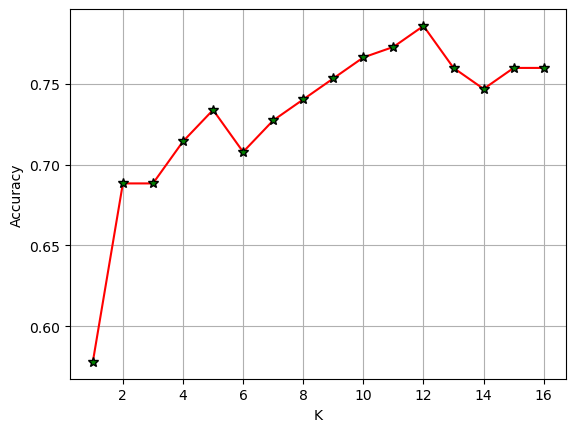

In [10]:
#plot graph to get the 'k'
import matplotlib.pyplot as plt
plt.plot(range(1,17),l,c='red',ms=7,mec='k',mfc='g',marker='*')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [ ]:
help(plt.plot)

In [12]:
knn=KNeighborsClassifier(n_neighbors=12)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)
y_pred

array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0])

In [13]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[90 11]
 [22 31]]


In [14]:
tn=cm[0][0]
fp=cm[0,1]
fn=cm[1,0]
tp=cm[1,1]
accuracy=(tn+tp)/(tn+tp+fn+fp)
print(accuracy)

0.7857142857142857


In [15]:
error_rate=1-accuracy
print(error_rate)

0.2142857142857143


In [16]:
# sensitivity(recall value) #Actual correct judgement
# specificity #
sensitivity=tp/(tp+fn)
specificity=tn/(fp+tn)
print("Sensitivity:",sensitivity)
print("Specificity:",specificity)

Sensitivity: 0.5849056603773585
Specificity: 0.8910891089108911


In [17]:
from sklearn.metrics import recall_score,
print(recall_score(y_test,y_pred))

SyntaxError: trailing comma not allowed without surrounding parentheses (2514603656.py, line 1)

In [18]:
ch=pd.read_csv('Churn.csv')
ch

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [19]:
ch.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [20]:
ch.dropna(inplace=True)
ch.drop(columns='customerID',inplace=True)
ch

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [21]:
ch=pd.get_dummies(ch)

In [22]:
x=ch.drop(columns='Churn_Yes')
y=ch['Churn_Yes']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=20)
l=[]
for i in range(1,20):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train,y_train)
    y_pred=knn.predict(x_test)
    l.append(accuracy_score(y_test,y_pred))
l

[0.7455579246624022,
 0.7889125799573561,
 0.7739872068230277,
 0.7846481876332623,
 0.7761194029850746,
 0.7846481876332623,
 0.7810945273631841,
 0.783226723525231,
 0.7803837953091685,
 0.7910447761194029,
 0.7867803837953091,
 0.7874911158493249,
 0.7846481876332623,
 0.7889125799573561,
 0.7867803837953091,
 0.7896233120113717,
 0.7903340440653873,
 0.7896233120113717,
 0.7917555081734187]

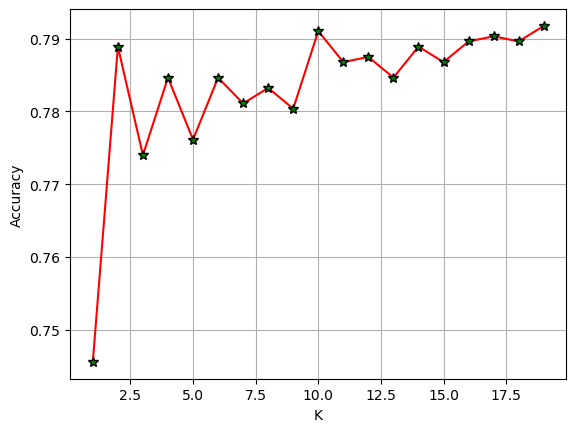

In [23]:
plt.plot(range(1,20),l,c='red',ms=7,mec='k',mfc='g',marker='*')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [24]:
# k=10
knn=KNeighborsClassifier(n_neighbors=i)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)
print("Accuracy:",accuracy_score(y_test,y_pred))

Accuracy: 0.7917555081734187


# SCALING
 - compulsory for knn

In [25]:
d=pd.read_csv('diabetes.csv')

In [26]:
x=d.drop(columns='Outcome')
y=d['Outcome']

In [27]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=20)

In [28]:
# normalize the data
# how? every data in a col divided by that col's max value

In [30]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.fit_transform(x_test)
print(x_train_scaled)
# print(x_test_scaled)

[[0.05882353 0.50251256 0.63157895 ... 0.37704918 0.25766326 0.11666667]
 [0.17647059 0.95979899 0.59649123 ... 0.46050671 0.09817859 0.21666667]
 [0.17647059 0.3919598  0.61403509 ... 0.48435171 0.08529542 0.3       ]
 ...
 [0.11764706 0.54271357 0.54385965 ... 0.37555887 0.02221235 0.        ]
 [0.23529412 0.57286432 0.56140351 ... 0.43070045 0.02132386 0.05      ]
 [0.52941176 0.82914573 0.77192982 ... 0.45305514 0.09951133 0.46666667]]


In [46]:
l=[]
for i in range(1,17):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_scaled,y_train)
    y_pred=knn.predict(x_test_scaled)
    l.append(accuracy_score(y_test,y_pred))
l

[0.6883116883116883,
 0.7077922077922078,
 0.7077922077922078,
 0.7272727272727273,
 0.7337662337662337,
 0.7272727272727273,
 0.7142857142857143,
 0.7597402597402597,
 0.7272727272727273,
 0.7467532467532467,
 0.7597402597402597,
 0.7597402597402597,
 0.7532467532467533,
 0.7792207792207793,
 0.7727272727272727,
 0.7857142857142857]

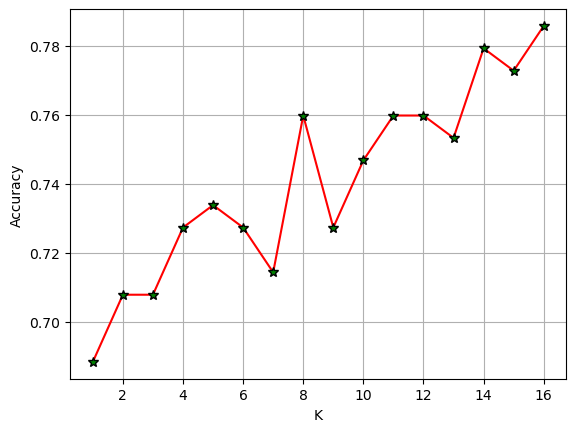

In [47]:
#plot graph to get the 'k'
import matplotlib.pyplot as plt
plt.plot(range(1,17),l,c='red',ms=7,mec='k',mfc='g',marker='*')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [ ]:
# thumb-rule k~ n^(1/2) 
# NOTE for 1-1000 (k btw 1-20)
#          1000-10000 (k btw 1-40)

In [38]:
df=pd.read_csv('churndata_processed.csv')
df #already normalised

,months,multiple,gb_mon,security,backup,protection,support,unlimited,contract,paperless,...,payment_Credit Card,payment_Mailed Check,internet_type_DSL,internet_type_Fiber Optic,internet_type_None,offer_Offer A,offer_Offer B,offer_Offer C,offer_Offer D,offer_Offer E
0,0.00,0,0.094118,0,0,1,0,0,0.0,1,...,0,0,1,0,0,0,0,0,0,0
1,0.00,1,0.200000,0,1,0,0,1,0.0,1,...,1,0,0,1,0,0,0,0,0,1
2,0.25,1,0.611765,0,0,0,0,1,0.0,1,...,0,0,0,1,0,0,0,0,1,0
3,0.25,0,0.141176,0,1,1,0,1,0.0,1,...,0,0,0,1,0,0,0,1,0,0
4,0.50,1,0.164706,0,0,0,0,1,0.0,1,...,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1.00,0,0.000000,0,0,0,0,0,1.0,1,...,0,0,0,0,1,0,0,0,0,0
7039,0.25,1,0.282353,1,0,1,1,1,0.5,1,...,0,1,0,0,0,0,0,1,0,0
7040,1.00,1,0.694118,0,1,1,0,1,0.5,1,...,1,0,0,1,0,0,0,0,0,0
7041,0.00,0,0.200000,1,0,0,0,1,0.0,1,...,0,0,1,0,0,0,0,0,0,0


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   months                     7043 non-null   float64
 1   multiple                   7043 non-null   int64  
 2   gb_mon                     7043 non-null   float64
 3   security                   7043 non-null   int64  
 4   backup                     7043 non-null   int64  
 5   protection                 7043 non-null   int64  
 6   support                    7043 non-null   int64  
 7   unlimited                  7043 non-null   int64  
 8   contract                   7043 non-null   float64
 9   paperless                  7043 non-null   int64  
 10  monthly                    7043 non-null   float64
 11  satisfaction               7043 non-null   float64
 12  churn_value                7043 non-null   int64  
 13  payment_Credit Card        7043 non-null   int64

In [48]:
x=df.drop(columns='churn_value')
y=df['churn_value']

In [49]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=20)

**The most effective way to get k:**

In [62]:
from sklearn.model_selection import GridSearchCV
params={'n_neighbors':range(1,21)}
grid=GridSearchCV(KNeighborsClassifier(),params,cv=5,scoring='accuracy')
grid.fit(x_train,y_train)
grid.best_params_ 

{'n_neighbors': 15}

In [56]:
l=[]
for i in range(1,20):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train,y_train)
    y_pred=knn.predict(x_test)
    l.append(accuracy_score(y_test,y_pred))
l
print(l.index(max(l)))

10


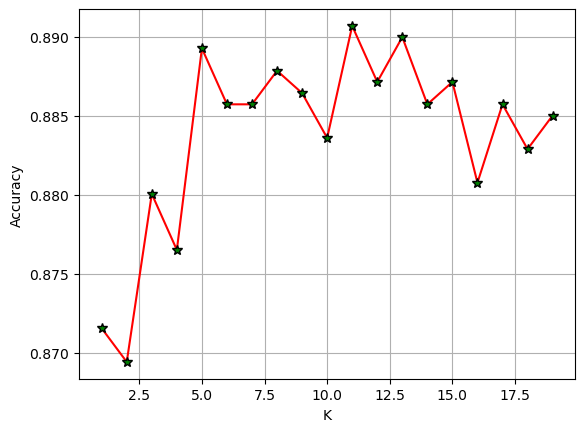

In [53]:
plt.plot(range(1,20),l,c='red',ms=7,mec='k',mfc='g',marker='*')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [ ]:
# The gridSearchCV method gives 15(accounts every parameter) while the loop one gives 11(on the basis of accuracy ONLY)

In [63]:
knn=KNeighborsClassifier(n_neighbors=11)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)
l.append(accuracy_score(y_test,y_pred))
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.95      0.93      1011
           1       0.86      0.74      0.79       398

    accuracy                           0.89      1409
   macro avg       0.88      0.84      0.86      1409
weighted avg       0.89      0.89      0.89      1409



In [64]:
knn=KNeighborsClassifier(n_neighbors=15)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)
l.append(accuracy_score(y_test,y_pred))
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.95      0.92      1011
           1       0.85      0.73      0.78       398

    accuracy                           0.89      1409
   macro avg       0.87      0.84      0.85      1409
weighted avg       0.89      0.89      0.88      1409



In [65]:
glass=pd.read_csv('glass.csv')
glass

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [66]:
glass.nunique()

RI      178
Na      142
Mg       94
Al      118
Si      133
K        65
Ca      143
Ba       34
Fe       32
Type      6
dtype: int64

In [67]:
glass.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [69]:
glass.duplicated().sum()

np.int64(1)

In [70]:
glass[glass.duplicated()]

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
39,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


In [71]:
glass.drop_duplicates(inplace=True)